# Generic orbits: batched (k, n) amplitude and flux maps

Increment C of the GPU/JAX port (`dev/PHASE5C.md`): Teukolsky amplitudes for
generic Kerr orbits as 2D Fourier coefficients over the (q_theta, q_r)
torus, contracted per mode to one (k, n) bin with an O(B*nq) working set.
Assertions embedded so re-execution is itself a test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hblteuk.geo import MiniGeo
from hblteuk.jax import solve_generic_mode_table, flux_modes

A, P, E, X = 0.9, 8.0, 0.3, 0.6
KMAX, NMIN, NMAX = 4, -6, 6
orbit = MiniGeo(A, P, E, X)
modes = [(2, 2, k, n) for k in range(-KMAX, KMAX + 1)
         for n in range(NMIN, NMAX + 1)]
l_arr = np.array([c[0] for c in modes])
m_arr = np.array([c[1] for c in modes])
k_arr = np.array([c[2] for c in modes])
n_arr = np.array([c[3] for c in modes])
print(f"{len(modes)} modes: (l, m) = (2, 2), k in [-{KMAX}, {KMAX}], "
      f"n in [{NMIN}, {NMAX}]")

117 modes: (l, m) = (2, 2), k in [-4, 4], n in [-6, 6]


In [2]:
sol = solve_generic_mode_table(orbit, -2, l_arr, m_arr, k_arr, n_arr,
                               nsamples=2**9, ntheta=2**7)
fx = flux_modes(sol.amplitudes, sol.m, sol.omega, sol.eigenvalues, A,
                k=sol.k, n=sol.n,
                carter_frequencies=orbit.carter_frequencies())
err = np.asarray(sol.errors).max(axis=1)
print(f"max relative error estimate: {err.max():.2e}")
assert err.max() < 1e-3
edot = np.asarray(fx.Edot)[:, 0]
qdot = np.asarray(fx.Qdot)[:, 0]
tot = edot.sum()
print(f"total Edot_inf over the map: {tot:.6e}")
assert tot > 0
print(f"superradiant modes: {(np.asarray(fx.Edot)[:, 1] < 0).sum()}/{len(modes)}")

max relative error estimate: 5.08e-05
total Edot_inf over the map: 3.818639e-05
superradiant modes: 83/117


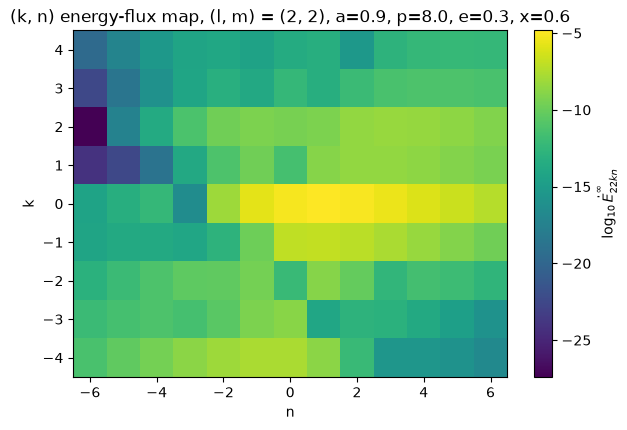

In [3]:
E2 = edot.reshape(2 * KMAX + 1, NMAX - NMIN + 1)
err2 = err.reshape(2 * KMAX + 1, NMAX - NMIN + 1)
masked = np.where(err2 < 1e-4, E2, np.nan)   # mask unconverged cells
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(np.log10(masked), origin="lower", aspect="auto",
               extent=[NMIN - 0.5, NMAX + 0.5, -KMAX - 0.5, KMAX + 0.5],
               cmap="viridis")
fig.colorbar(im, label=r"$\log_{10}\dot{E}^\infty_{22kn}$")
ax.set_xlabel("n"); ax.set_ylabel("k")
ax.set_title(f"(k, n) energy-flux map, (l, m) = (2, 2), "
             f"a={A}, p={P}, e={E}, x={X}")
plt.show()
# spectral falloff: map corners sit far below the peak
corners = [E2[0, 0], E2[0, -1], E2[-1, 0], E2[-1, -1]]
assert E2.max() / max(corners) > 1e3

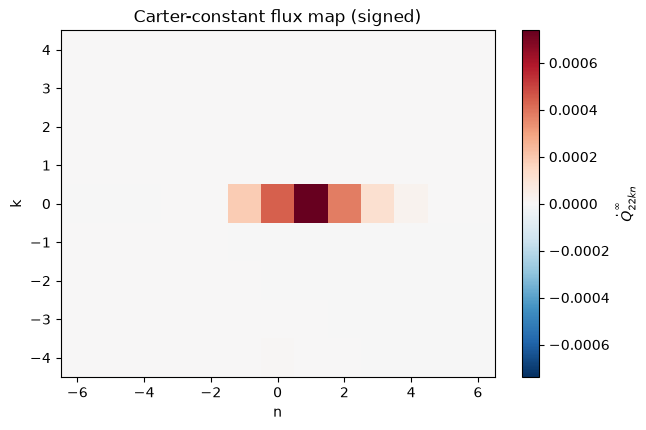

In [4]:
Q2 = qdot.reshape(2 * KMAX + 1, NMAX - NMIN + 1)
lim = np.nanmax(np.abs(Q2))
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(Q2, origin="lower", aspect="auto",
               extent=[NMIN - 0.5, NMAX + 0.5, -KMAX - 0.5, KMAX + 0.5],
               cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.colorbar(im, label=r"$\dot{Q}^\infty_{22kn}$")
ax.set_xlabel("n"); ax.set_ylabel("k")
ax.set_title("Carter-constant flux map (signed)")
plt.show()
# equatorial check embedded: Carter flux vanishes identically at x = 1
eq = MiniGeo(A, 10.0, 0.2, 1.0)
cR, cTh, cPh = eq.carter_frequencies()
assert abs(cR) < 1e-12 and abs(cPh) < 1e-12